In [41]:
import kagglehub
import pandas as pd

# Download latest version
path = kagglehub.dataset_download("atharvaingle/crop-recommendation-dataset")

df = pd.read_csv(path+'/Crop_recommendation.csv')
df.head()

Using Colab cache for faster access to the 'crop-recommendation-dataset' dataset.


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [42]:
import numpy as np
import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

Using GPU

In [43]:
dev = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(dev)

cuda


List all the column names

In [44]:
df.columns.tolist()

['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Train Test Split

In [45]:
from sklearn.model_selection import train_test_split

X = df.drop('label', axis=1)
y = df['label']
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

Standardize the data

In [46]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

Label Encoding

In [47]:
from sklearn.preprocessing import LabelEncoder
labels = y.unique()
labeler = LabelEncoder()
y_train = labeler.fit_transform(y_train)
y_test = labeler.transform(y_test)
y_val = labeler.transform(y_val)
labels.size

22

Converting this pandas df into tensors

In [48]:
X_train = torch.tensor(
    X_train,
    dtype=torch.float32,
    device=dev
)

X_test = torch.tensor(
    X_test,
    dtype=torch.float32,
    device=dev
)

y_train = torch.tensor(
    y_train,
    dtype=torch.long,
    device=dev
)

y_test = torch.tensor(
    y_test,
    dtype=torch.long,
    device=dev
)
# Fix: Initialize directly as float32
X_val = torch.tensor(X_val, dtype=torch.float32, device=dev)


y_val = torch.tensor(
    y_val,
    dtype=torch.long,
    device=dev
)

Creating the MLP

In [54]:
# Model
net = nn.Sequential(
    nn.Linear(7, 32),
    nn.BatchNorm1d(32),
    nn.ReLU(),
    nn.Dropout(0.25),
    nn.Linear(32, 22)
).to(dev)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
opt = torch.optim.Adam(net.parameters(), lr=0.001)

train_losses = []
val_losses = []
val_accuracies = []

# Ensure validation input is float32
X_val = X_val.float()

# Training
for epoch in range(2000):

    net.train()

    opt.zero_grad()

    train_pred = net(X_train)
    loss = criterion(train_pred, y_train)

    loss.backward()
    opt.step()

    train_losses.append(loss.item())

    # Validation
    net.eval()

    with torch.no_grad():
        val_pred = net(X_val)
        val_loss = criterion(val_pred, y_val)

        predicted_classes = val_pred.argmax(dim=1)

        accuracy = (
            predicted_classes == y_val
        ).float().mean()

    val_losses.append(val_loss.item())
    val_accuracies.append(accuracy.item())

    if (epoch + 1) % 200 == 0:
        print(
            f"Epoch {epoch+1}/2000 | "
            f"Train Loss: {loss.item():.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Val Accuracy: {accuracy.item():.4f}"
        )


Epoch 200/2000 | Train Loss: 1.0434 | Val Loss: 0.9610 | Val Accuracy: 0.8606
Epoch 400/2000 | Train Loss: 0.5455 | Val Loss: 0.4215 | Val Accuracy: 0.9303
Epoch 600/2000 | Train Loss: 0.3783 | Val Loss: 0.2614 | Val Accuracy: 0.9667
Epoch 800/2000 | Train Loss: 0.3000 | Val Loss: 0.1886 | Val Accuracy: 0.9697
Epoch 1000/2000 | Train Loss: 0.2404 | Val Loss: 0.1490 | Val Accuracy: 0.9818
Epoch 1200/2000 | Train Loss: 0.2035 | Val Loss: 0.1232 | Val Accuracy: 0.9848
Epoch 1400/2000 | Train Loss: 0.1872 | Val Loss: 0.1063 | Val Accuracy: 0.9788
Epoch 1600/2000 | Train Loss: 0.1704 | Val Loss: 0.0940 | Val Accuracy: 0.9788
Epoch 1800/2000 | Train Loss: 0.1474 | Val Loss: 0.0844 | Val Accuracy: 0.9818
Epoch 2000/2000 | Train Loss: 0.1416 | Val Loss: 0.0760 | Val Accuracy: 0.9848


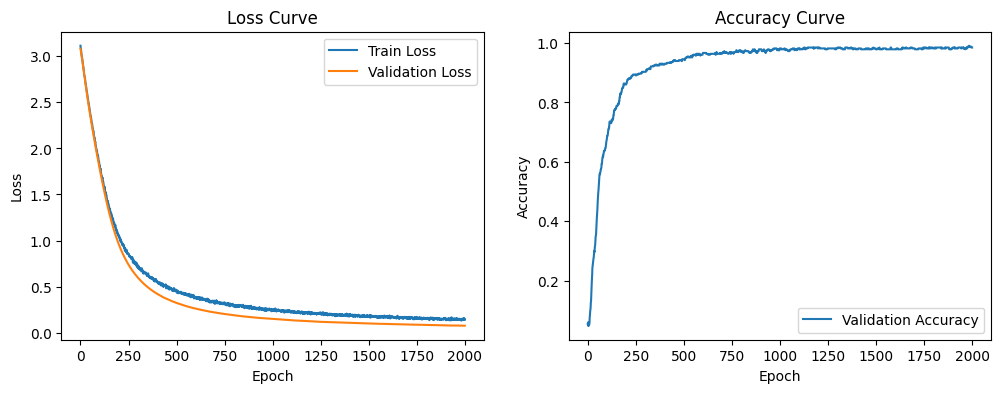

In [55]:
import matplotlib.pyplot as plt

# Plotting the loss and accuracy curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy Curve")

plt.show()